In [43]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output

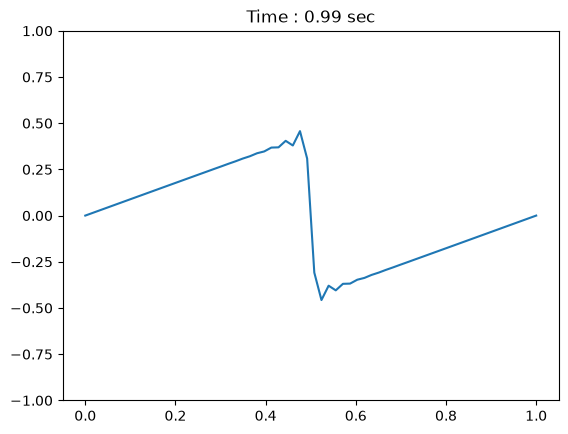

In [44]:
Nx = 64
x = np.linspace(0,1.0,Nx)
dx = x[1]

Nt = 100
T = 1.0
t = np.linspace(0,T,Nt)
dt = t[1]

u0 = np.sin(2 * np.pi * x)
up = u0.copy()
un = up.copy()

alpha = dt / (2 * dx)

for k in range(1,Nt):
    un = up.copy()
    for ite in range(10):
        f = un[1:-1] - up[1:-1] + alpha * (un[2:]**2 - un[:-2]**2) / 2 
        J = np.diag(np.ones_like(un[1:-1]), k=0) + np.diag(alpha * un[2:-1], k=1) + np.diag(-alpha * un[1:-2], k=-1)
        du = np.linalg.solve(J, -f)
        un[1:-1] += du

    un[1:-1] += 0.00001*(un[2:] - 2 * un[1:-1] + un[:-2]) / dx**2
    up = un.copy()
        
#f = un[i] - up[i] + alpha * (un[i + 1]**2 - un[i - 1]**2) / 2
#df/dun[i] = 1
#df/dun[i+1] = alpha * un[i+1]
#df/dun[i-1] = -alpha * un[i-1]

    if k % 2 == 0:
        clear_output(wait=True)
        plt.plot(x, un)
        plt.ylim(-1,1)
        plt.title(f"Time : {k * dt:.2f} sec")
        plt.show()
        plt.pause(0.01)